# Week 4

이번 Week4에서는 Week3에서 살펴본 사전학습 모델을 **우리 리뷰 데이터로 직접 파인튜닝(Fine-Tuning)** 해볼 거예요. 데이터 준비부터 학습, 평가, 예측까지 하나의 파이프라인으로 연결해봅시다!

그런데 학습을 마친 모델도 아직은 **내 파이썬 코드 안에서** 호출하는 형태입니다.
예를 들어 쇼핑몰 서버(BE)가 새로 올라온 리뷰가 긍정인지 부정인지 우리 모델에게 물어보고 싶어도, 방법이 없죠. 우리가 만든 AI 모델을 실제 서비스에 붙여야 비로소 '리뷰의 감정을 분류해주는' 하나의 서비스 기능이 완성됩니다.  

그래서 이번 주차에는 파인튜닝한 모델을 **다른 프로그램이 요청을 보내 결과를 받아갈 수 있는 API 형태로 띄워보는 과정**, 즉 **모델 서빙(Model Serving)** 까지 진행해볼 예정입니다.

> **📌 이번 실습은 가급적이면 Google Colab의 T4 GPU에서 진행해주세요!**
> CPU에서는 BERT 파인튜닝에 오랜 시간이 걸릴 수 있어요.

[4주 흐름](../README.md)과 [실행 환경 안내](../docs/runtime.md)를 먼저 확인해주세요.


### 이번 주차의 학습 목표

- fine-tuning 파이프라인 구성
- 모델 서빙(Model Serving)의 개념과 필요성 이해
- FastAPI를 활용하여 모델을 API로 감싸는 구조 익히기


### 파일 구조

```text
gdg-7th-ai-mission/
├── week4/
│   ├── README.md
│   ├── week4.md
│   ├── week4_mission.ipynb
│   └── images/
├── artifacts/  # 실습 결과를 저장하면 생성됩니다.
│   └── week4/
│       ├── training/           # 학습 중 결과
│       └── service/
│           ├── saved_model/   # 모델과 tokenizer
│           ├── model.py
│           ├── api.py
│           └── server.log
├── docs/runtime.md
└── pyproject.toml
```


### ⚓️ Mission

- **[제공 코드]** 는 그대로 실행해주세요.
- **[⚓️ 미션]** 에서는 TODO 안내에 따라 `None`을 코드로 바꿔주세요.
- **생각해보기**는 아래의 답변 셀에 작성해주세요.
- 출력과 그래프는 실제로 실행한 결과를 바탕으로 정리해주세요.
- 코드를 수정했다면 해당 셀부터 아래로 다시 실행해주세요.

이번 주차는 이전 주차의 결과 파일 없이 진행할 수 있어요. 학습 실행 부분의 빈칸을 채운 뒤, 위에서부터 실행해주세요.


### 실행 환경 준비하기

**Colab과 로컬 모두 아래 설치 셀을 그대로 실행해주세요.** 현재 노트북의 Python 환경에 필요한 패키지를 설치합니다. 이전 주차를 실행하지 않아도 괜찮아요.

설치가 끝나면 **커널(Colab은 세션)을 한 번 재시작**하고, 다음 라이브러리 셀부터 실행해주세요. 설치 전에 불러온 패키지가 메모리에 남는 것을 방지하기 위해서예요.

로컬에서는 [실행 환경 안내](../docs/runtime.md)에 따라 Python 3.12 커널을 선택해주세요. Colab에서는 T4 GPU 런타임을 선택합니다.


In [1]:
# [제공 코드] Colab·로컬에서 현재 노트북의 Python에 필요한 패키지를 설치합니다.
import importlib.util
import shutil
import subprocess
import sys

packages = [
    'numpy>=1.26,<3', 'tensorflow>=2.16,<3', 'torch>=2.6,<3',
    'transformers>=4.46,<6', 'datasets>=3,<6', 'accelerate>=1,<2',
    'fastapi>=0.115,<1', 'uvicorn>=0.30,<1', 'requests>=2.31,<3',
]

# uv가 있으면 사용하고, 없으면 현재 Python의 pip로 설치합니다.
if shutil.which('uv'):
    command = ['uv', 'pip', 'install', '--python', sys.executable]
else:
    if importlib.util.find_spec('pip') is None:
        subprocess.check_call([sys.executable, '-m', 'ensurepip', '--upgrade'])
    command = [sys.executable, '-m', 'pip', 'install']
subprocess.check_call(command + packages)
print('설치 완료! 커널(Colab은 세션)을 재시작한 뒤 다음 셀부터 실행해주세요.')

# 결과를 Drive에 보관할 때만 사용합니다.
# from google.colab import drive
# drive.mount('/content/drive')


설치 완료! 커널(Colab은 세션)을 재시작한 뒤 다음 셀부터 실행해주세요.


In [1]:
# [제공 코드] 라이브러리와 실습 경로를 준비합니다.
import json
import os
import sys
from pathlib import Path

# Transformers의 모델 학습·추론에는 PyTorch를 사용합니다.
os.environ['USE_TF'] = '0'
os.environ['USE_TORCH'] = '1'

import numpy as np
import requests
import torch
from datasets import Dataset
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, pipeline, set_seed,
)

ROOT_DIR = Path.cwd().resolve()
for candidate in [ROOT_DIR, *ROOT_DIR.parents]:
    if (candidate / 'pyproject.toml').is_file():
        ROOT_DIR = candidate
        break
SAVE_DIR = ROOT_DIR / 'artifacts' / 'week4'
# Drive를 연결했다면 실제 저장 위치에 맞게 바꿔주세요.
SAVE_DIR = Path('/content/artifacts/week4')
SERVICE_DIR = SAVE_DIR / 'service'
MODEL_DIR = SERVICE_DIR / 'saved_model'
TRAIN_DIR = SAVE_DIR / 'training'
SERVICE_DIR.mkdir(parents=True, exist_ok=True)

PORT = 8000  # 이미 사용 중이면 다른 번호로 바꾸고 이 셀부터 다시 실행해주세요.
API_BASE_URL = f'http://127.0.0.1:{PORT}'

SEED = 42
set_seed(SEED)
print('GPU 사용 가능:', torch.cuda.is_available())
print('실습 결과 저장 위치:', SAVE_DIR)


GPU 사용 가능: True
실습 결과 저장 위치: /content/artifacts/week4


## Mission1 (파인튜닝 모델 구성하기)

Week3에서는 사전학습 모델을 가져와서 우리 데이터로 추가학습하는 Fine-Tuning의 개념을 배웠어요.

이번 Week4에서는 Fine-Tuning 과정을 하나의 파이프라인으로 구성해봅시다!

모델은 Week3에서 구조를 분석했던 `klue/bert-base`를 사용할 것이고, 해당 모델에 **리뷰 데이터**를 Fine-Tuning 시켜서 최종적으로 긍정/부정을 출력하는 이진 분류 모델을 만드는 것이 목표에요.

1주차의 데이터 준비와 tokenizing, 2주차의 학습 & 평가 & 예측까지, 앞에서 배운 개념이 하나의 Fine-Tuning 파이프라인으로 어떻게 연결되는지 경험해봅시다!



#### 1. 데이터 다운로드 및 데이터 전처리

Week1에서 사용한 데이터 다운로드와 전처리 코드를 가져왔어요. 평점이 4~5점이면 긍정(1), 1~2점이면 부정(0)으로 구분합니다.

이번에는 학습 시간을 줄이기 위해 전체 20만개 중 4,000개만 무작위로 골라서 사용할게요. (여유가 있다면 데이터 수를 늘려보셔도 괜찮아요!)

마지막에는 리뷰와 정답을 text, label을 가진 딕셔너리로 묶어, 다음 단계에서 Dataset으로 바꿀 수 있도록 준비했어요.


In [2]:
# [제공 코드] Week1에서 사용한 코드로 리뷰 데이터를 준비합니다.
import tensorflow as tf
# TensorFlow는 다운로드에만 사용하므로 GPU 메모리를 사용하지 않도록 합니다.
tf.config.set_visible_devices([], 'GPU')

path_to_file = tf.keras.utils.get_file(
    'naver_shopping.txt',
    'https://raw.githubusercontent.com/bab2min/corpus/master/sentiment/naver_shopping.txt',
    cache_dir=str(Path.cwd() / 'data'), cache_subdir='',
)

text = Path(path_to_file).read_text(encoding='utf-8')
print('Length of text: {} characters'.format(len(text)))
print(text[:300])

# [제공 코드] 사용할 줄을 고르고 중복을 제거합니다.
def filter_rows(text):
    rows = []
    seen = set()

    for row in text.splitlines():
        parts = row.split('\t', 1)
        if len(parts) != 2:
            continue

        rating, review = parts
        if rating not in ['1', '2', '4', '5'] or not review.strip():
            continue
        if row in seen:
            continue

        seen.add(row)
        rows.append(row)

    return rows

# [제공 코드] Week1의 라벨 생성 함수
def make_labels(rows):
    labels = []
    for row in rows:
        rating = int(row.split('\t', 1)[0])
        label = 1 if rating >= 4 else 0
        labels.append(label)

    return np.array(labels, dtype=np.int64).reshape(-1, 1)

rows = filter_rows(text)

# 학습 시간을 줄이기 위해 일부 리뷰만 무작위로 고릅니다.
SAMPLE_SIZE = 4000
rng = np.random.default_rng(SEED)
indices = rng.choice(len(rows), size=min(SAMPLE_SIZE, len(rows)), replace=False)
rows = [rows[int(i)] for i in indices]

labels = make_labels(rows)
review_texts = [row.split('\t', 1)[1] for row in rows]
records = [
    {'text': review, 'label': int(label[0])}
    for review, label in zip(review_texts, labels)
]
print('사용할 리뷰 수:', len(records))
print('리뷰 예시:', records[:3])


20623547/20623547 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Length of text: 8537926 characters
5	배공빠르고 굿
2	택배가 엉망이네용 저희집 밑에층에 말도없이 놔두고가고
5	아주좋아요 바지 정말 좋아서2개 더 구매했어요 이가격에 대박입니다. 바느질이 조금 엉성하긴 하지만 편하고 가성비 최고예요.
2	선물용으로 빨리 받아서 전달했어야 하는 상품이었는데 머그컵만 와서 당황했습니다. 전화했더니 바로주신다했지만 배송도 누락되어있었네요.. 확인안하고 바로 선물했으면 큰일날뻔했네요..이렇게 배송이 오래걸렸으면 사는거 다시 생각했을거같아요 아쉽네요..
5	민트색상 예뻐요. 옆 손잡이는 거는 용도로도 사용되네요 ㅎㅎ
2	비추합니다 계란 뒤
사용할 리뷰 수: 4000
리뷰 예시: [{'text': '기초마지막단계에서 꼭쓰고있어요 7년째 사용중이예요. 흡수도 잘되고 없어선안되요', 'label': 1}, {'text': 'ㅕㅇ혀ㅕㅍ더챠렫파폳', 'label': 0}, {'text': '아기 침대에 깔아주려고 샀는데 적당히 까슬거리고 한번만 접어서 깔아주면 딱 크기도 좋네요~', 'label': 1}]


#### 2. HuggingFace 사전학습 모델 불러오기

Week3에서 사용했던 코드를 가져와, **`klue/bert-base` 모델과 짝이 되는 tokenizer**를 불러와요.

Week3에서는 모델의 구조를 살펴봤다면, 이번에는 같은 모델을 우리 리뷰 데이터로 학습시켜볼 거예요. `num_labels=2`는 긍정·부정 두 가지로 분류한다는 뜻입니다.


In [3]:
# [제공 코드] Week3에서 사용한 모델과 tokenizer를 불러옵니다.
MODEL_NAME = 'klue/bert-base'
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2)

print('전체 파라미터 수:', f'{model.num_parameters():,}')


config.json:   0%|          | 0.00/425 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/289 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/248k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/495k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  445MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: klue/bert-base
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


전체 파라미터 수: 110,618,882


#### 3. Dataset 구성하기

리뷰와 라벨을 Hugging Face의 **Dataset**으로 바꿉니다. 전체의 80%는 훈련용, 20%는 검증용으로 나누어 사용할 거예요.

훈련용과 검증용 데이터셋의 **class(긍정·부정) 비율이 비슷하도록** `stratify_by_column='label'`을 설정합니다.

In [4]:
# [제공 코드] 앞에서 만든 딕셔너리 리스트를 Dataset으로 바꿉니다.
dataset = Dataset.from_list(records)

# label을 분류 범주를 나타내는 ClassLabel 자료형으로 바꿉니다.
dataset = dataset.class_encode_column('label')

# 훈련용과 검증용 데이터셋의 class 비율이 비슷하도록 stratify_by_column='label'을 설정합니다.
split_dataset = dataset.train_test_split(
    test_size=0.2, seed=SEED, stratify_by_column='label',
)
train_dataset = split_dataset['train']
validation_dataset = split_dataset['test']  # 이번에는 검증용으로 사용합니다.

print('훈련용 리뷰 수:', len(train_dataset))
print('검증용 리뷰 수:', len(validation_dataset))


Stringifying the column:   0%|          | 0/4000 [00:00<?, ? examples/s]

Casting to class labels:   0%|          | 0/4000 [00:00<?, ? examples/s]

훈련용 리뷰 수: 3200
검증용 리뷰 수: 800


#### 4. Tokenizing 함수 구현하기

이제 문장을 모델에 넣을 수 있도록 숫자로 바꿔봅시다!

`truncation=True`는 너무 긴 문장을 자르고, `padding='max_length'`는 짧은 문장에 패딩을 채우는 설정입니다. 이번에는 문장 길이를 **최대 128토큰**으로 맞춰볼 거예요.

`map()`은 Dataset의 문장에 `tokenize()`를 적용하는 부분입니다. 원본 문장을 정수 입력으로 바꾸는 과정을 확인해보아요.


In [5]:
# [제공 코드] tokenizer로 문장을 숫자로 바꿉니다.
MAX_LENGTH = 128

def tokenize(batch):
    return tokenizer(
        batch['text'], truncation=True,
        padding='max_length', max_length=MAX_LENGTH,
    )

tokenized_train = train_dataset.map(tokenize, batched=True, remove_columns=['text'])
tokenized_validation = validation_dataset.map(tokenize, batched=True, remove_columns=['text'])
print('변환된 항목:', tokenized_train.column_names)
print('첫 문장의 토큰 수:', len(tokenized_train[0]['input_ids']))


Map:   0%|          | 0/3200 [00:00<?, ? examples/s]

Map:   0%|          | 0/800 [00:00<?, ? examples/s]

변환된 항목: ['label', 'input_ids', 'token_type_ids', 'attention_mask']
첫 문장의 토큰 수: 128


**실행 결과 확인**

변환된 데이터에 `input_ids`, `attention_mask`, `label`이 있는지 확인해주세요.


#### 5. Fine-Tuning 학습 구성하기

모델과 데이터를 준비했으니, 이제 실제로 학습시켜봅시다!

`TrainingArguments`에는 학습률, Epoch 수, 배치 크기 등 학습 설정을 담습니다. 이번에는 **학습률 0.00002, 2 Epoch, 배치 크기 8**로 진행해볼 거예요.

`Trainer`는 모델, 훈련·검증 데이터, 학습 설정을 받아 학습과 평가를 돌리는 도구입니다.

**[⚓️ 미션]** 마지막 `...`를 바꿔, `trainer`의 학습을 실행하는 코드를 작성해주세요.

**HINT:** Week2에서는 `model.fit()`으로 학습했죠. Hugging Face의 `Trainer`에서는 **`train()`** 메서드를 사용합니다.


In [6]:
# [제공 코드] 학습 중 정확도를 계산하는 함수입니다.
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return {'accuracy': float(np.mean(predictions == labels))}

# [제공 코드] 학습 설정을 준비합니다.
training_args = TrainingArguments(
    output_dir=str(TRAIN_DIR),
    learning_rate=2e-5,
    num_train_epochs=2,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    eval_strategy='epoch',
    save_strategy='no',
    report_to='none',
    seed=SEED,
    data_seed=SEED,
    dataloader_num_workers=0,
    dataloader_pin_memory=torch.cuda.is_available(),
    use_cpu=not torch.cuda.is_available(),  # 로컬에서는 CPU, Colab GPU에서는 CUDA 사용
)

# [제공 코드] 모델, 데이터, 평가 함수를 Trainer에 전달합니다.
trainer = Trainer(
    model=model, # 모델
    args=training_args, # 학습 설정
    train_dataset=tokenized_train,# 훈련용 데이터셋
    eval_dataset=tokenized_validation, # 검증용 데이터셋
    processing_class=tokenizer,# 토크나이저
    compute_metrics=compute_metrics, # 평가함수
)

# [⚓️ 미션] trainer의 파인튜닝 학습을 실행해주세요.
trainer.train()


Epoch,Training Loss,Validation Loss,Accuracy
1,No log,0.268789,0.927500
2,0.302832,0.269815,0.930000


TrainOutput(global_step=800, training_loss=0.26364185810089114, metrics={'train_runtime': 166.4481, 'train_samples_per_second': 38.45, 'train_steps_per_second': 4.806, 'total_flos': 420977688576000.0, 'train_loss': 0.26364185810089114, 'epoch': 2.0})

**⭐️ 개념 정리**

파인튜닝에서는 하이퍼파라미터 설정에 따라 학습 시간과 효율이 결정됩니다. 아래 하이퍼파라미터의 역할을 정리해주세요.

- `learning_rate`: 학습률은 무엇이며, 너무 크거나 작으면 어떤 문제가 생길까요?
- `num_train_epochs`: 훈련 데이터를 반복해서 학습하는 횟수입니다. 너무 많이 반복하면 어떤 문제가 생길까요?
- `per_device_train_batch_size`: 장치 하나에서 한 번에 학습하는 데이터 수입니다. 값을 늘리면 GPU 메모리 사용량은 어떻게 달라질까요?


- learning_rate: 손실함수의 최솟값을 찾아가는 역전파 과정에서 어떤 보폭으로 조정할지 결정하는 파라미터
  - 학습률이 너무 크면 최솟값을 지나치거나, 발산하여 학습에 실패할 수 있다.
  - 학습률이 너무 작으면 극솟값에 갇히거나, 최솟값에 도달하는데 시간이 오래걸린다.

- num_train_epochs: 훈련 데이터셋을 학습하는 과정을 몇 번 반복할지 정하는 횟수. 너무 많이 반복하면 훈련 데이터를 외워 과적합이 발생할 수 있다.

- per_device_train_batch_size: 학습 디바이스(GPU 등) 당 한번에 학습하는 데이터 수. 값이 클수록 학습 속도가 빨라질 수 있지만, GPU 메모리 사용량이 늘어나며 메모리 부족 현상이 발생할 수 있다.


#### 6. 모델 성능 평가하기

학습을 마쳤다면, 검증 데이터로 모델의 성능을 확인해볼까요?

`trainer.evaluate()`는 검증 데이터의 손실과 정확도를 계산합니다. 정확도를 계산하는 함수는 앞에서 `compute_metrics`로 전달했어요.


In [7]:
# [제공 코드] 검증 데이터로 학습한 모델을 평가합니다.
metrics = trainer.evaluate()
print(f"검증 손실: {metrics['eval_loss']:.4f}")
print(f"검증 정확도: {metrics['eval_accuracy']:.1%}")


Training Loss,Validation Loss,Epoch,Accuracy
0.302832,0.269815,2,0.930000


검증 손실: 0.2698
검증 정확도: 93.0%


**실행 결과 확인**

검증 정확도가 0~100% 사이로 출력되는지 확인해주세요. 데이터 수와 학습 설정에 따라 결과는 달라질 수 있어요.


#### 7. 감정 분석 테스트하기

마지막으로, 학습한 모델에 실제 리뷰 문장을 넣어봅시다!

`pipeline()`으로 학습한 모델과 tokenizer를 연결하면 문장의 감정을 예측할 수 있어요. 예시 문장들을 원하는 리뷰로 바꿔도 좋아요!!

출력되는 `score`는 **예측한 감정에 대한 점수**입니다.

In [8]:
# [제공 코드]  Fine-Tuning한 모델을 사용하여 실제 리뷰를 예측합니다.
example_sentences = [
    '배송도 빠르고 품질도 좋아요',
    '상품이 망가져서 왔어요 다시는 안 사요',
    '디자인은 예쁜데 사이즈가 너무 작아요',
    '제품이 정말 좋아요 근데 배송은 느리네요',
    '또 살 것 같진 않은데 나쁘진 않아요'
]
classifier = pipeline('text-classification', model=model, tokenizer=tokenizer)
results = classifier(example_sentences, truncation=True, max_length=MAX_LENGTH)

for text, result in zip(example_sentences, results):
    label = '긍정' if result['label'] == 'LABEL_1' else '부정'
    print('문장:', text)
    print(f"예측: {label} / 점수: {result['score']:.4f}")
    print()


문장: 배송도 빠르고 품질도 좋아요
예측: 긍정 / 점수: 0.9962

문장: 상품이 망가져서 왔어요 다시는 안 사요
예측: 부정 / 점수: 0.9967

문장: 디자인은 예쁜데 사이즈가 너무 작아요
예측: 부정 / 점수: 0.9963

문장: 제품이 정말 좋아요 근데 배송은 느리네요
예측: 긍정 / 점수: 0.9923

문장: 또 살 것 같진 않은데 나쁘진 않아요
예측: 긍정 / 점수: 0.6965



**생각해보기:**

- 이번 실습의 전체적인 파인튜닝 과정을 정리할 겸, 사용한 사전학습 모델, 데이터 수, 최대 토큰 길이, 학습률, Epoch 수, 배치 크기를 정리해주세요.
- 파인튜닝한 모델의 검증 정확도는 어떤가요?
- 파인튜닝한 모델은 감정을 잘 예측하나요? 리뷰 3개의 예측은 어땠나요? 예상과 달랐던 결과가 있다면 함께 정리해주세요.


1. 파인튜닝 설정
- klue/bert-base를 사전학습 모델로 사용하고, 2진 감정 분류용으로 파인 튜닝했다.
- 데이터는 4000개의 리뷰를 무작위로 골라서 80%는 훈련용(3200개), 20%는 검증용(800개)으로 나누어 사용했다.
- 최대 토큰 길이는 128토큰으로 긴 문장은 자르고, 짧은 문장은 최대 토큰 길이에 맞춰 패딩한다.
- 학습률은 0.00002`learning_rate=2e-5'
- Epoch 수는 2
- Batch 크기는 8로 설정한다.

2. 모델 검증 정확도
- 검증 손실: 0.2698
- 검증 정확도: 93.0%

3. 리뷰 감정 예측 결과

문장: 배송도 빠르고 품질도 좋아요
예측: 긍정 / 점수: 0.9962

문장: 상품이 망가져서 왔어요 다시는 안 사요
예측: 부정 / 점수: 0.9967

문장: 디자인은 예쁜데 사이즈가 너무 작아요
예측: 부정 / 점수: 0.9963

문장: 또 살 것 같진 않은데 나쁘진 않아요
예측: 긍정 / 점수: 0.6965
- 애매한 문장에 대한 결과가 0.5에 가깝게 나왔다.


문장: 제품이 정말 좋아요 근데 배송은 느리네요
예측: 긍정 / 점수: 0.9923
- 1주차 모델은 해당 문장을 부정으로 판단했는데 이번 모델에서는 긍정으로 평가한다.
- 하지만 긍정점수가 예상보다 지나치게 높다. attention이 정말이 좋아요를 강조하는 관계를 반영해서 그런 것 같다.
- 긍정과 부정이 섞인 문장의 확률을 잘 판단하지 못 하는 것 같다.

## Mission2 (FastAPI로 모델 서빙하기)

Mission1에서 만든 감정 분석 모델은 지금 **내 파이썬 코드 안에서만** 호출할 수 있습니다.
이렇게 만든 모델을 **다른 프로그램이 요청을 보내 결과를 받아갈 수 있는 형태로 띄워두는 것**을 **모델 서빙(Model Serving)** 이라고 합니다. 이번 미션에서는 **FastAPI**로 감정 분석 모델을 감싸서, 백엔드가 호출할 수 있는 API로 만들어보겠습니다.


### API란?

먼저 API가 무엇인지 알아보아요!

**API**는 프로그램끼리 서로 기능을 주고받기 위한 **약속된 창구**입니다.

백엔드 팀은 우리 모델 코드도, 내부가 어떻게 동작하는지도 모릅니다. 하지만 **정해진 주소로 정해진 형식의 요청**만 보내면 모델 응답을 받을 수 있습니다.

예시를 들어볼게요. 우리는 매일 날씨 앱으로 날씨를 확인합니다. 하지만 날씨 앱 개발자가 직접 날씨를 관측해서 올리는 것은 아닙니다. 대신 기상청이 열어둔 날씨 API에 요청을 보내 날씨 정보를 받아와서 화면에 보여줍니다. 날씨 앱 개발자는 기상청이 날씨를 어떻게 관측하는지 몰라도, 정해진 주소로, 정해진 형식에 맞게 요청만 보내면 결과를 받아올 수 있기 때문이죠.

```markdown
[날씨 앱] → 요청: "오늘 서울 날씨 요청"
↓
[기상청 API] → 관측 데이터에서 서울 날씨 조회
↓
[날씨 앱] ← 응답: {"기온": 18, "날씨": "맑음"}
```


이번 미션도 똑같습니다. 날씨 앱 자리에 **쇼핑몰 백엔드**가, 기상청 자리에 **우리가 만든 감정 분석 모델**이 들어간다고 생각하면 됩니다.


### FastAPI란?

**FastAPI**는 이런 **API 서버**를 쉽게 만들 수 있게 해주는 **파이썬 도구**입니다.

정해진 주소(예: `/sentiment`)로 요청이 들어오면, 우리가 연결해둔 함수(`predict()`)를 실행하고 결과를 돌려줍니다.

파이썬 기반이라 우리가 만든 모델 코드를 그대로 연결할 수 있어서, AI 모델 서빙에 많이 사용됩니다.

> 💡 이번 미션의 목표는 FastAPI 문법을 익히는 것이 아니라, **모델을 API로 감싸는 구조**를 이해하는 것입니다. 코드는 제공된 그대로 사용하고, 각 부분이 어떤 역할을 하는지에 집중해주세요!


#### 0. 모델 저장하기

Mission1에서 파인튜닝한 모델과 토크나이저를 `saved_model` 폴더에 저장합니다. 이후 서버는 이 폴더에서 모델을 불러오게 됩니다.

결과는 준비 셀에서 설정한 `MODEL_DIR`에 저장해요. API에서 같은 라벨과 최대 길이를 사용하도록 설정도 함께 기록합니다. **제공 코드를 그대로 실행해주세요.**


In [9]:
# [제공 코드] Mission 1에서 학습한 모델과 tokenizer를 저장합니다.
model.config.id2label = {0: 'LABEL_0', 1: 'LABEL_1'}
model.config.label2id = {'LABEL_0': 0, 'LABEL_1': 1}
model.save_pretrained(MODEL_DIR)
tokenizer.save_pretrained(MODEL_DIR)

(SERVICE_DIR / 'inference_config.json').write_text(
    json.dumps({'max_length': int(MAX_LENGTH)}), encoding='utf-8',
)
print('모델과 tokenizer 저장 위치:', MODEL_DIR)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

모델과 tokenizer 저장 위치: /content/artifacts/week4/service/saved_model


#### 1. 모델을 함수로 감싸기


`%%writefile`은 셀의 내용을 파일로 저장하는 Jupyter·Colab 명령어입니다.

뒤에서 만들 API 서버에서도 함수를 사용할 수 있도록, 이 아래에 나오는 모델 로드 & 감정 예측 코드를 `model.py` 파일로 저장해둘게요.

In [10]:
%%writefile "{SERVICE_DIR}/model.py"
import json
from pathlib import Path
from transformers import pipeline

# model.py와 같은 폴더의 저장 모델을 한 번 불러옵니다.
BASE_DIR = Path(__file__).resolve().parent
config = json.loads((BASE_DIR / 'inference_config.json').read_text(encoding='utf-8'))

# 분류기 pipeline 생성
classifier = pipeline(
    "text-classification",
    model=str(BASE_DIR / "saved_model"),
    tokenizer=str(BASE_DIR / "saved_model"),
    device=-1,  # 서빙 실습은 CPU에서 진행해 학습용 GPU와 별도로 사용합니다.
)

#
def predict(text: str) -> dict:
  """
  리뷰를 입력하면 모델이 예측한 감정과 점수를 반환합니다.

  입력: text (str) - 리뷰 문장
  출력: dict - {"label": "긍정" 또는 "부정", "score": float}
  """
    result = classifier(text, truncation=True, max_length=config['max_length'])[0]

    label = "긍정" if result["label"] == "LABEL_1" else "부정"

    return {"label": label, "score": round(result["score"], 4)}


Writing /content/artifacts/week4/service/model.py


`classifier`는 0단계에서 저장한 모델과 토크나이저를 불러와 감정 분류를 준비합니다. `predict()` 함수는 `classifier`의 결과를 `result`에 담아, 라벨에 따라 긍정/부정과 점수를 돌려줍니다.


predict 함수에 원하는 리뷰를 넣어보세요!

**모델을 다시 학습했다면**, 모델 저장 셀부터 아래로 다시 실행해주세요. 아래 셀은 저장된 모델을 다시 불러오며, API에도 반영하려면 서버 실행 셀도 다시 실행해야 합니다.


In [12]:
# [제공 코드] 저장 모델을 다시 불러옵니다. 재학습·저장 후에도 이 셀을 재실행해주세요.
import importlib

service_path = str(SERVICE_DIR.resolve())
if service_path in sys.path:
    sys.path.remove(service_path)
sys.path.insert(0, service_path)
importlib.invalidate_caches()

if 'model' in sys.modules:
    serving_model = importlib.reload(sys.modules['model'])
else:
    serving_model = importlib.import_module('model')
predict = serving_model.predict

predict("배송은 느렸지만 품질은 아주 마음에 들어요.")


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

{'label': '긍정', 'score': 0.9965}

출력 형태 예시입니다. 실제 감정과 점수는 학습 결과에 따라 달라질 수 있어요.

```text
{'label': '긍정', 'score': 0.98}
```


참고로, 모델을 불러오는 작업은 수백MB 크기인 모델 파일을 메모리에 올리는 것이기 때문에 몇 초(서비스에서는 긴 시간입니다..)가 걸립니다. 반면, 이미 불러온 모델은 파일을 다시 읽지 않고 예측할 수 있어요. 실제 예측 시간은 장비와 문장 길이에 따라 달라집니다.

만약 `classifier`를 `predict()` 함수 안에 두면, 요청이 들어올 때마다 모델을 새로 불러오는 형태가 되어 응답 하나를 받는데 몇 초씩 걸리게 될 것입니다. 그래서 `classifier`는 **함수 바깥**에 둠으로써, 무거운 모델은 서버가 켜질 때 **한 번만** 불러오도록 한 것입니다.



#### 2. 함수를 API로 감싸기


In [13]:
%%writefile "{SERVICE_DIR}/api.py"
from fastapi import FastAPI
from fastapi.openapi.docs import get_swagger_ui_html
from pydantic import BaseModel
from model import predict # 앞서 만든 predict 함수

# Colab에서도 같은 서버를 호출하도록 상대 경로를 사용합니다.
app = FastAPI(docs_url=None, servers=[{"url": "."}])

@app.get("/docs", include_in_schema=False)
def docs():
    return get_swagger_ui_html(openapi_url="openapi.json", title="감정 분석 API")

class SentimentRequest(BaseModel):   # BE가 보내는 형식
    text: str

class SentimentResponse(BaseModel):  # 우리가 돌려주는 형식
    label: str
    score: float

@app.post("/sentiment", response_model=SentimentResponse)
def sentiment(request: SentimentRequest):
    return SentimentResponse(**predict(request.text))


Writing /content/artifacts/week4/service/api.py


위에서 만들었던, 리뷰 문장을 넣으면 감정 분석 결과를 돌려주는 `predict()` 함수를 기억하시죠? 이 함수를 감싸는 `sentiment()`라는 함수가 보입니다. 이 함수는 요청으로 들어온 리뷰 문장(`request.text`)을 `predict()`에 넘기고, 그 결과를 응답 형식에 맞춰 돌려주는 역할을 합니다.

함수 위에 붙은 `@app.post("/sentiment")`는 이 함수를 `/sentiment` 주소와 연결해줍니다. 즉, `/sentiment` 주소로 리뷰 문장이 들어오면 `sentiment()` → `predict()` 순서로 실행되어 감정 분석 결과를 돌려주는 것이죠.

`SentimentRequest`, `SentimentResponse`는 백엔드와 주고받을 **데이터 형식에 대한 약속**입니다. `SentimentRequest`의 `text`에는 분석할 리뷰 문장이 담기고, `SentimentResponse`에는 모델이 예측한 감정 `label`과 예측 점수 `score`가 담깁니다.


**생각해보기:**

- 요청/응답 형식을 백엔드와 **미리 맞춰두어야 하는 이유**는 무엇일까요?


서로의 내부 코드를 모르고 데이터 형식으 소통하기 때문이다. 요청이 실패하거나 결과를 잘못 해석하는 것을 막기 위해 형식을 맞춰둔다.


#### 3. 서버 실행하기


In [14]:
# [제공 코드] 현재 노트북과 같은 Python 환경에서 서버를 실행합니다.
import socket
import subprocess
import time

# 이 셀에서 실행한 이전 서버를 종료하고, 새 모델로 서버를 다시 시작합니다.
if 'server_process' in globals() and server_process.poll() is None:
    server_process.terminate()
    try:
        server_process.wait(timeout=15)
    except subprocess.TimeoutExpired:
        server_process.kill()
        server_process.wait()

# 다른 프로그램이 사용 중인 포트를 잘못 호출하지 않도록 먼저 확인합니다.
with socket.socket() as port_check:
    port_check.setsockopt(socket.SOL_SOCKET, socket.SO_REUSEADDR, 1)
    try:
        port_check.bind(('127.0.0.1', PORT))
    except OSError as error:
        raise RuntimeError(f'{PORT}번 포트가 사용 중입니다. 준비 셀의 PORT를 바꿔주세요.') from error

log_path = SERVICE_DIR / 'server.log'
with log_path.open('w', encoding='utf-8') as log_file:
    server_process = subprocess.Popen(
        [sys.executable, '-m', 'uvicorn', 'api:app', '--host', '127.0.0.1', '--port', str(PORT)],
        cwd=str(SERVICE_DIR), stdout=log_file, stderr=subprocess.STDOUT,
    )

try:
    deadline = time.monotonic() + 120
    while time.monotonic() < deadline:
        if server_process.poll() is not None:
            raise RuntimeError(log_path.read_text(encoding='utf-8'))
        try:
            if requests.get(f'{API_BASE_URL}/openapi.json', timeout=1).status_code == 200:
                print(f'서버 준비 완료: {API_BASE_URL}/docs')
                break
        except requests.RequestException:
            pass
        time.sleep(0.5)
    else:
        raise TimeoutError('서버 시작이 지연됩니다. server.log를 확인해주세요.')
except Exception:
    if server_process.poll() is None:
        server_process.kill()
        server_process.wait()
    raise


서버 준비 완료: http://127.0.0.1:8000/docs


- `api:app`: `api.py` 파일 안의 `app` 객체를 실행한다는 뜻입니다.
- `--port`: 준비 셀의 `PORT` 번호로 요청을 받습니다. 기본값은 8000입니다. `127.0.0.1`은 지금 실습하는 컴퓨터 안에서 접속할 주소예요.
- `subprocess.Popen()`: 서버를 **별도 프로세스**로 실행합니다. 서버는 요청을 기다리며 계속 켜져 있어야 하므로, 노트북의 다음 셀도 실행할 수 있도록 따로 띄워둡니다.
- `stdout=log_file`: 서버에서 출력되는 내용을 `server.log` 파일에 저장합니다.


In [15]:
print('\n'.join(log_path.read_text(encoding='utf-8').splitlines()[-10:]))



Loading weights: 100%|██████████| 201/201 [00:00<00:00, 5043.95it/s]
INFO:     Started server process [4102]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://127.0.0.1:8000 (Press CTRL+C to quit)
INFO:     127.0.0.1:37858 - "GET /openapi.json HTTP/1.1" 200 OK


서버가 켜지는 데 몇 초 정도 걸립니다. 로그에 `Application startup complete.`가 출력되면 서버가 켜진 것입니다.


In [16]:
# [제공 코드] Colab이면 셀 아래에, 로컬이면 접속 주소를 표시합니다.
try:
    from google.colab import output
except ImportError:
    print(f'브라우저에서 {API_BASE_URL}/docs 를 열어주세요.')
else:
    output.serve_kernel_port_as_iframe(PORT, path='/docs', height=650)


<IPython.core.display.Javascript object>

위 셀은 환경을 자동으로 구분합니다. Colab에서는 셀 아래에 API 문서 화면이 나타납니다. 로컬에서는 `http://127.0.0.1:8000/docs`를 열어주세요. FastAPI가 자동으로 만들어준 **API 문서**가 나타납니다. `/sentiment` → `Try it out`을 눌러 직접 리뷰 문장을 보내볼 수 있습니다.

<p align="left">
  <img src="./images/swagger1.png" width="700">
</p>

`/sentiment`를 펼친 뒤, 오른쪽의 `Try it out` 버튼을 눌러주세요.

<p align="left">
  <img src="./images/swagger2.png" width="700">
</p>

`text`에 분석하고 싶은 리뷰 문장을 입력하고, `Execute` 버튼을 눌러 요청을 보냅니다.

<p align="left">
  <img src="./images/swagger3.png" width="700">
</p>

`Response body`에서 모델이 예측한 감정 `label`과 예측 점수 `score`를 확인할 수 있습니다.

**[⚓️ 미션]** `/docs` 화면에서 직접 요청을 보내고, 결과 화면을 캡처해주세요.

아래 답변 셀에 캡처를 첨부하거나, WIL에 작성해주세요.


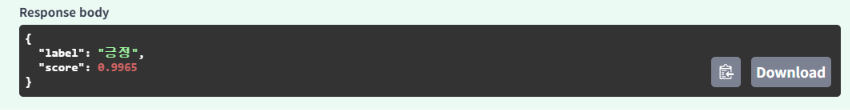

#### 4. 백엔드처럼 호출해보기


In [17]:
import requests

response = requests.post(
    f'{API_BASE_URL}/sentiment',
    json={"text": "배송도 빠르고 품질도 좋아요"},
    timeout=60,
)
print("상태 코드:", response.status_code)
print(response.json())


상태 코드: 200
{'label': '긍정', 'score': 0.9962}


출력 형태 예시입니다. 실제 감정과 점수는 학습 결과에 따라 달라질 수 있어요.

```text
{'label': '긍정', 'score': 0.98}
```


서버를 켜둔 상태에서 `requests`로 요청을 보내봅시다. 실제 백엔드도 이 방식으로 우리 모델에 리뷰를 보내고 결과를 받아가게 됩니다.

아래 제공 코드는 **리뷰 3개를 정상 형식으로 요청**한 뒤, `{"text": "..."}` 대신 `{"review": "..."}`처럼 **약속과 다른 형식으로 요청**합니다.

각 요청의 상태 코드와 응답을 비교해보아요!


In [18]:
# [제공 코드] 리뷰 3개를 API로 보냅니다.
reviews = [
    '배송도 빠르고 품질도 좋아요',
    '상품이 망가져서 왔어요 다시는 안 사요',
    '디자인은 예쁜데 사이즈가 너무 작아요',
]
for review in reviews:
    response = requests.post(
        f'{API_BASE_URL}/sentiment',
        json={'text': review}, timeout=60,
    )
    print('문장:', review)
    print('상태 코드:', response.status_code)
    print('응답:', response.json())
    print()

# 약속한 text 대신 review라는 항목 이름으로 보내봅니다.
wrong_response = requests.post(
    f'{API_BASE_URL}/sentiment',
    json={'review': '배송도 빠르고 품질도 좋아요'}, timeout=60,
)
print('잘못된 형식의 상태 코드:', wrong_response.status_code)
print('응답:', wrong_response.json())


문장: 배송도 빠르고 품질도 좋아요
상태 코드: 200
응답: {'label': '긍정', 'score': 0.9962}

문장: 상품이 망가져서 왔어요 다시는 안 사요
상태 코드: 200
응답: {'label': '부정', 'score': 0.9967}

문장: 디자인은 예쁜데 사이즈가 너무 작아요
상태 코드: 200
응답: {'label': '부정', 'score': 0.9963}

잘못된 형식의 상태 코드: 422
응답: {'detail': [{'type': 'missing', 'loc': ['body', 'text'], 'msg': 'Field required', 'input': {'review': '배송도 빠르고 품질도 좋아요'}}]}


**생각해보기:**

- 정상 요청과, 약속한 항목이 없는 요청의 상태 코드·응답은 어떻게 달랐나요?


정상 요청은 상태코드 200과 예측 결과 ['label' : ... , 'score': ...]를 받았다.
text 대신 review라는 이름으로 보낸 요청은 상태코드 422가 반환됐고, 오류 메세지를 받았다.

#### 5. 실습 서버 종료하기

실습을 마쳤다면 서버를 종료해주세요. 다시 요청을 보내려면 서버 실행 셀부터 실행하면 됩니다.


In [ ]:
# [제공 코드] 이 노트북에서 실행한 서버를 종료합니다.
if 'server_process' in globals() and server_process.poll() is None:
    server_process.terminate()
    server_process.wait(timeout=15)
    print('서버를 종료했습니다.')
else:
    print('이 커널에서 실행 중인 서버가 없습니다.')


### 정리

이번 미션에서 만든 구조를 다시 정리해보면 다음과 같습니다.

```markdown
model.py → 모델을 불러오고 예측하는 코드 (AI 파트)
api.py   → 요청을 받아 model.py에 넘기고, 결과를 돌려주는 창구 (FastAPI)
requests → 정해진 형식으로 요청을 보내고 결과를 받아가는 쪽 (BE)
```

이처럼 **요청을 받아 모델을 실행하고 결과를 돌려주는 흐름**은 다른 모델에도 활용할 수 있습니다. 예를 들어 Week3에서 만든 RAG 챗봇을 서빙하고 싶다면, `model.py`의 `predict()` 대신 `run_rag()`를 만들고, `api.py`에 `/chat` 주소를 연결할 수 있습니다. 입력과 응답 형식도 RAG 함수에 맞게 정해주면 되겠죠! 앞으로 프로젝트에서 AI 기능을 백엔드와 연결할 때, 이번 미션의 구조를 그대로 활용해보세요!


### 마무리

-  Mission1, Mission2를 진행한 `.ipynb` 파일을 github에 올려주세요.
- **개념 정리**와 **생각해보기**는 노트북의 답변 셀에 원하는 분량만큼 작성해주세요.
- WIL에는 알게 된 점, 막힌 지점, 해결 방법을 300자 이상 작성해주세요.

### 끝으로…

모든 미션코스가 종료되었네요! Week1부터 Week4까지 고생 많으셨습니다.

이로써 저희는 텍스트 데이터 전처리와 모델 학습, RAG, 파인튜닝까지 자연어 처리의 큼지막한 개념들을 한번씩 훑어보게 되었습니다. 개개인이 가진 사전 지식에 따라 어렵게 느껴진 부분도, 익숙하게 느껴진 부분도 있었을 것 같아요. 학기 중이라는 걸 고려하면, 결코 한 주에 가볍게 소화할 만한 내용은 아니었다고 생각해요. (특히 week3 고생 많으셨을 것 같습니다.. )
처음 접하신 분들께는 새로운 개념을 공부하는 시간이, 이미 알고 계신 분들께는 개념을 다시 정리하고 코어타임을 통해 다른 사람과 공유하는 시간이 되었을까요? 어찌 되었든 모두가 얻어가는 게 있는 미션코스였다면 너무 좋을 것 같습니다.

AI 미션 코스를 구성하면서, 다른 파트 미션들처럼 코드를 작성하는 것보다는 개념을 이해하고 정리해보는 시간을 더 많이 가져보려고 했습니다. Tokenizer, Attention, Fine-Tuning처럼 생소한 개념들은 코드를 따라 치는 것만으로 이해하기 어렵기 때문이에요.

물론 코드를 직접 작성해보는 경험도 중요하지만, 요즘은 AI 도구들이 코드 자체는 어느 정도 잘 구성해주는 시대가 되었습니다. 따라서 코드가 어떤 단계에서 왜 필요한지, 지금 내가 수행하는 과정이 전체 AI 파이프라인에서 어떤 역할을 하는지 이해하지 못한다면 이후 더 복잡한 프로젝트를 진행할 때 어려움을 겪을 수 있다고 생각했습니다.

그래서 Week1~3은 개념 정리와 생각해보기의 분량을 늘리고, 핵심 코드만 구현하는 방향으로 구성했습니다. 그리고 Week4에서는 직접 Fine-Tuning 파이프라인을 구성하고, 만든 모델을 API로 감싸 서빙까지 해보았습니다.

이제 앞으로 본격적인 **기획 및 개발 코스**가 시작될 텐데, 이번 미션 코스에서 학습했던 내용들이 앞으로의 프로젝트를 진행하는 데 도움이 되었으면 좋겠습니다. 😃

기말고사에 좋은 결과 있으시길 바랍니다. 🍀 저희 **12/14(월) 기획 코스** 때 다시 뵈어요! 😊
